# PL9 · Diffusion & Multimodality 

**Generative AI · Laboratory class (PL) · 120 minutes**

You will build a **diffusion model from scratch** on tiny 2-D data — small enough to train in seconds, so every concept is visible in a plot — and then use a **pretrained CLIP** model to explore multimodality.

**Learning goals**
1. Implement the forward (noising) process and a noise schedule.
2. Train a denoiser whose only job is to **predict the noise**.
3. Sample with **DDPM** and **DDIM**, and see the quality–speed trade-off.
4. Add class conditioning and **classifier-free guidance**, and watch the guidance scale.
5. Use **CLIP** for zero-shot classification and image–text retrieval.
6. Probe a real multimodal model's strengths and failure modes.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup & data | 10 min |
| 1 | Forward process & schedule | 15 min |
| 2 | Train a denoiser | 20 min |
| 3 | Sampling: DDPM vs DDIM | 20 min |
| 4 | Conditioning & guidance | 20 min |
| 5 | CLIP: zero-shot & retrieval | 25 min |
| 6 | Probing a multimodal model | 5 min |
| 7 | Results & report | 5 min |
| ★ | Bonus: image diffusion, HyDE-style search | at home |

**Deliverable:** this notebook, executed, with the plots of Parts 1–4, the CLIP results of Part 5, and short answers to every ❓ question. Cells marked `# TODO` are yours. Run top to bottom.

## Part 0 · Setup & data (10 min)

A **GPU is optional** today: the 2-D model trains in seconds on CPU. For Part 5 (CLIP), a GPU is faster but not required. The bonus B1 (Stable Diffusion) **does** need a GPU.

In [ ]:
!pip -q install torch scikit-learn matplotlib open_clip_torch

In [1]:
import torch, torch.nn as nn
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_moons
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


Our dataset is **two interleaving moons** — a clearly structured 2-D shape, so you can *see* whether the model learned the distribution. Each point also has a **class label** (which moon), which we use in Part 4.

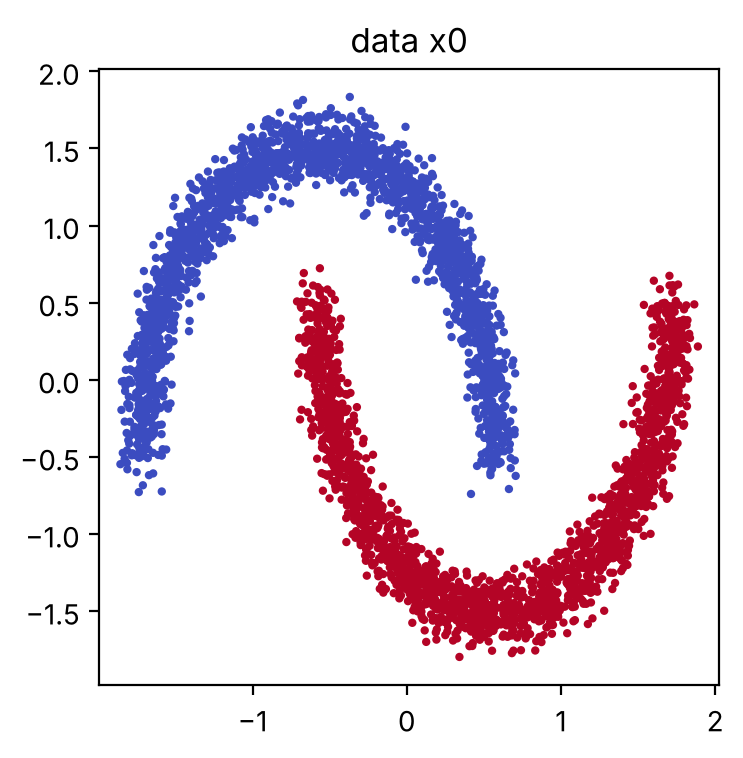

In [2]:
def sample_data(n):
    X, y = make_moons(n_samples=n, noise=0.06)
    X = (X - X.mean(0)) / X.std(0)                 # standardise to ~N(0,1) scale
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

X, y = sample_data(4000)
plt.figure(figsize=(4, 4))
plt.scatter(X[:, 0], X[:, 1], s=4, c=y, cmap="coolwarm"); plt.title("data x0"); plt.axis("equal"); plt.show()

## Part 1 · Forward process & schedule (15 min)

The forward process gradually turns data into noise. We need a **noise schedule** `ᾱ_t` (abar) that goes from ≈1 (no noise) at t=0 to ≈0 (pure noise) at t=T. Implement the **cosine schedule** (Nichol & Dhariwal, 2021), which keeps more signal in the middle than a linear one.

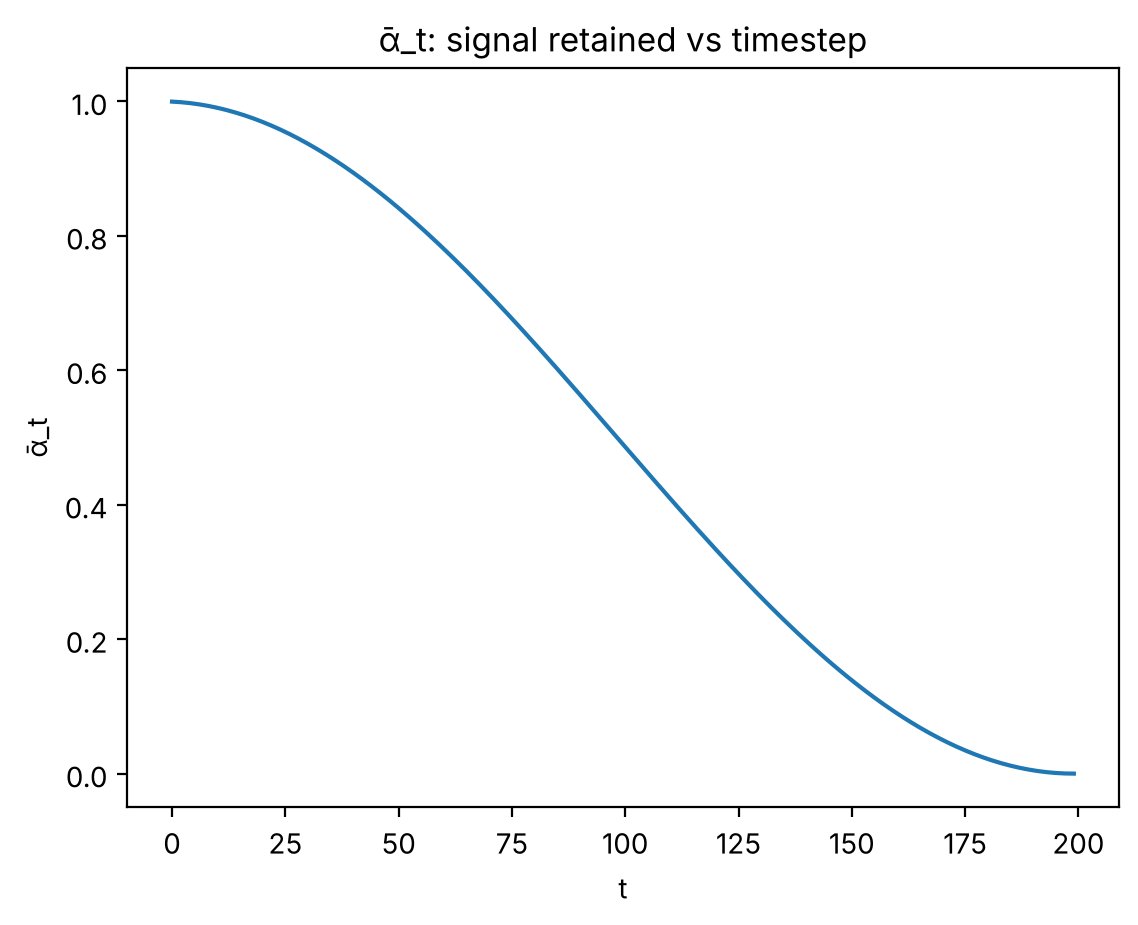

In [3]:
import math
T = 200

def cosine_schedule(T, s=0.008):
    t = torch.linspace(0, T, T + 1) / T
    f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2
    abar = (f / f[0])[1:]
    alphas = torch.cat([abar[:1], abar[1:] / abar[:-1]])
    betas = (1 - alphas).clamp(0, 0.999)
    alphas = 1 - betas
    abar = torch.cumprod(alphas, dim=0)
    return betas, alphas, abar

betas, alphas, abar = cosine_schedule(T)
assert abs(abar[0] - 1) < 0.05 and abar[-1] < 0.05
plt.plot(abar); plt.title("ᾱ_t: signal retained vs timestep"); plt.xlabel("t"); plt.ylabel("ᾱ_t"); plt.show()

The key identity lets us jump to any noise level in one shot:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\; \varepsilon,\qquad \varepsilon\sim\mathcal N(0,I)$$

Implement `q_sample`, then visualise the same batch of moons at increasing t.

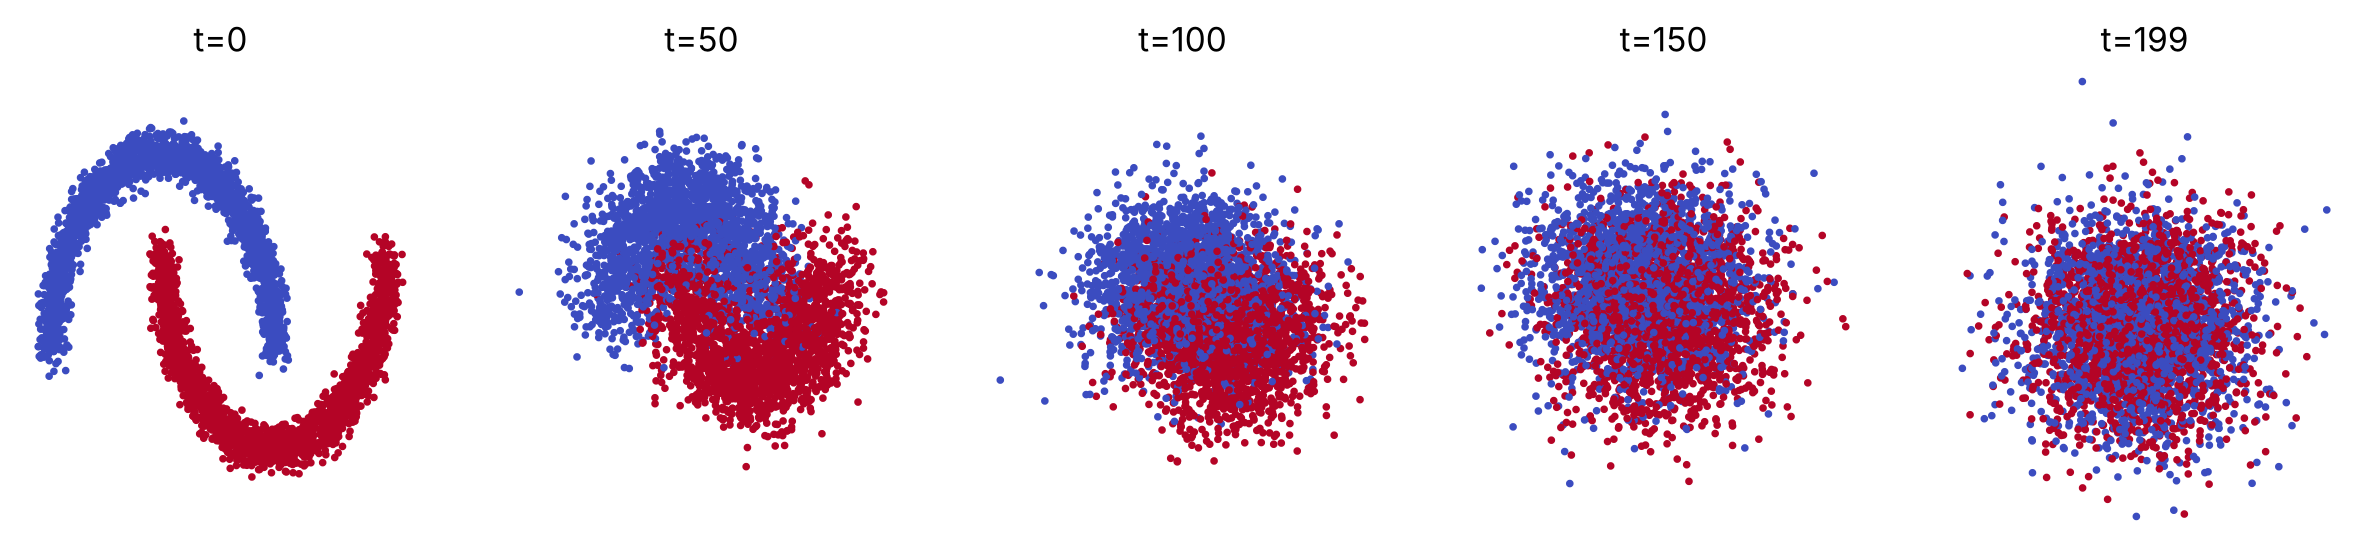

In [4]:
def q_sample(x0, t, noise):
    """Add t steps of noise to x0 in one shot. t is a LongTensor of shape (B,).
    x_t = sqrt(abar[t]) * x0 + sqrt(1 - abar[t]) * noise   (broadcast over the 2 dims)."""
    ab = abar.to(x0.device)[t.to(x0.device)].unsqueeze(1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, tt in zip(axes, [0, 50, 100, 150, 199]):
    tb = torch.full((len(X),), tt, dtype=torch.long)
    xt = q_sample(X, tb, torch.randn_like(X))
    ax.scatter(xt[:, 0], xt[:, 1], s=3, c=y, cmap="coolwarm"); ax.set_title(f"t={tt}"); ax.axis("equal"); ax.axis("off")
plt.show()

❓ **Q1.** At which t do the two moons stop being distinguishable? Replace the cosine schedule with a **linear** one Note that the classic values `betas = linspace(1e-4, 0.02, T)` were designed for **T = 1000**; with our T = 200 they must be scaled by 1000/T, otherwise the process never reaches pure noise and re-plot `ᾱ_t`. Which schedule destroys the structure sooner? Why might keeping signal longer help training?

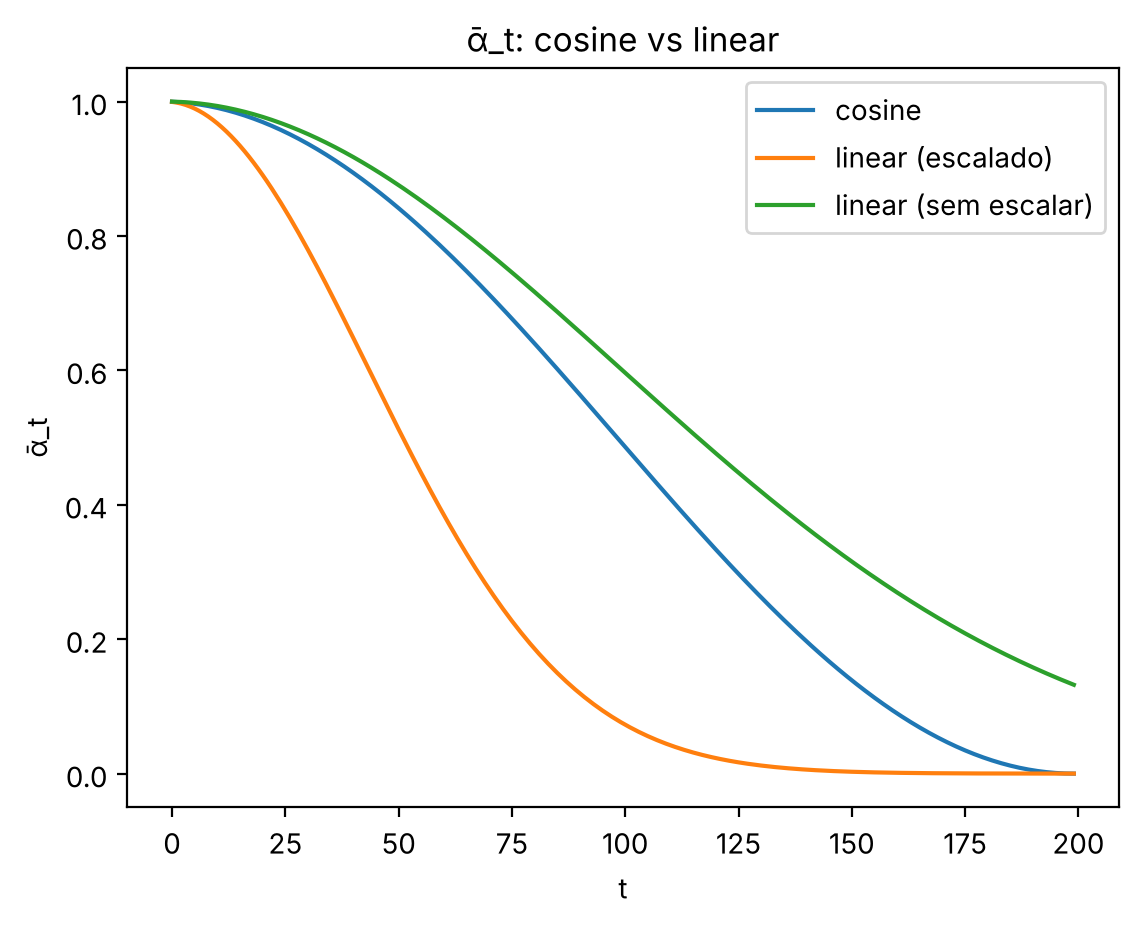

ᾱ final  cosine: 6.071638125604295e-08 | linear escalado: 3.031836786249187e-05 | linear sem escalar: 0.1321827620267868
cosine -> primeiro t com ᾱ < 0.5: 99 | ᾱ < 0.1: 158
linear -> primeiro t com ᾱ < 0.5: 51 | ᾱ < 0.1: 94


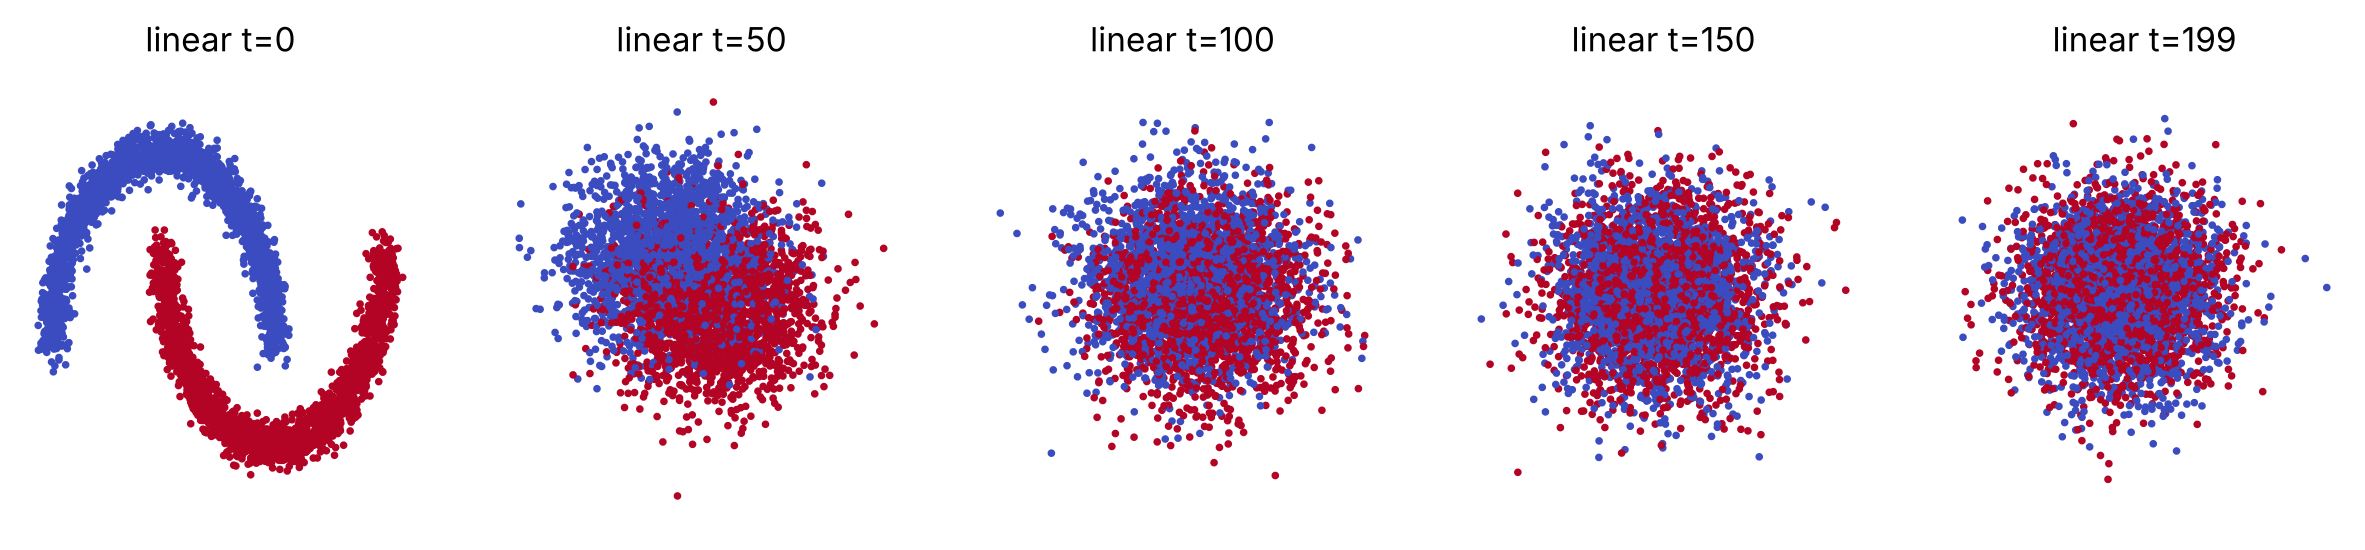

In [5]:
betas_lin = torch.linspace(1e-4 * 1000 / T, 0.02 * 1000 / T, T)
abar_lin = torch.cumprod(1 - betas_lin, dim=0)
betas_raw = torch.linspace(1e-4, 0.02, T)
abar_raw = torch.cumprod(1 - betas_raw, dim=0)

plt.plot(abar, label="cosine")
plt.plot(abar_lin, label="linear (escalado)")
plt.plot(abar_raw, label="linear (sem escalar)")
plt.xlabel("t"); plt.ylabel("ᾱ_t"); plt.legend(); plt.title("ᾱ_t: cosine vs linear"); plt.show()
print("ᾱ final  cosine:", abar[-1].item(), "| linear escalado:", abar_lin[-1].item(), "| linear sem escalar:", abar_raw[-1].item())
for nome, ab_ in [("cosine", abar), ("linear", abar_lin)]:
    print(nome, "-> primeiro t com ᾱ < 0.5:", int((ab_ < 0.5).nonzero()[0]), "| ᾱ < 0.1:", int((ab_ < 0.1).nonzero()[0]))

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, tt in zip(axes, [0, 50, 100, 150, 199]):
    noise = torch.randn_like(X)
    xt = abar_lin[tt].sqrt() * X + (1 - abar_lin[tt]).sqrt() * noise
    ax.scatter(xt[:, 0], xt[:, 1], s=3, c=y, cmap="coolwarm"); ax.set_title(f"linear t={tt}"); ax.axis("equal"); ax.axis("off")
plt.show()

## Part 2 · Train a denoiser (20 min)

The network takes a noisy point `x_t` and the timestep `t`, and predicts the **noise** that was added. We give it `t` through a small sinusoidal embedding (same idea as positional encodings).

In [6]:
def time_embedding(t, dim=32):
    """Map integer timesteps to a smooth vector (sinusoidal)."""
    t = t.float().unsqueeze(1)
    freqs = torch.exp(torch.linspace(0, np.log(1000), dim // 2, device=t.device))
    ang = t * freqs.unsqueeze(0)
    return torch.cat([ang.sin(), ang.cos()], dim=1)

class Denoiser(nn.Module):
    def __init__(self, hid=128, tdim=32, n_classes=0):
        super().__init__()
        self.tdim = tdim
        self.n_classes = n_classes
        if n_classes:
            self.cls_emb = nn.Embedding(n_classes + 1, tdim)   # +1 = the "null"/unconditional label
        in_dim = 2 + tdim + (tdim if n_classes else 0)
        self.net = nn.Sequential(nn.Linear(in_dim, hid), nn.SiLU(),
                                 nn.Linear(hid, hid), nn.SiLU(),
                                 nn.Linear(hid, hid), nn.SiLU(),
                                 nn.Linear(hid, 2))

    def forward(self, x, t, c=None):
        h = [x, time_embedding(t, self.tdim)]
        if self.n_classes:
            h.append(self.cls_emb(c))
        return self.net(torch.cat(h, dim=1))

print(sum(p.numel() for p in Denoiser().parameters()), "parameters")

37762 parameters


The training loss is exactly the one from the lecture: sample a random t, make `x_t`, and regress the predicted noise onto the true noise. Fill the loss.

step 0: loss 0.972


step 500: loss 0.513


step 1000: loss 0.442


step 1500: loss 0.453


step 2000: loss 0.456


step 2500: loss 0.419


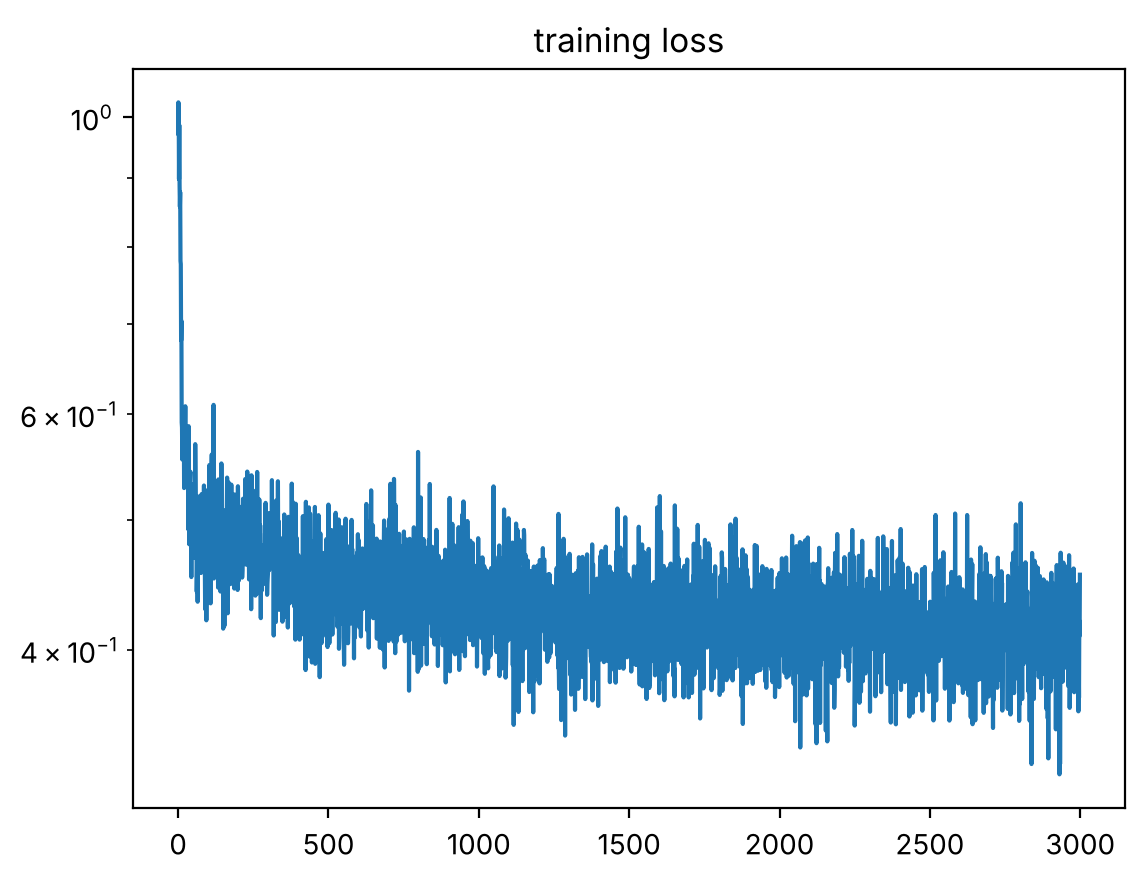

loss médio dos últimos 200 passos: 0.41251604035496714


In [7]:
def diffusion_loss(model, x0, c=None):
    B = x0.shape[0]
    t = torch.randint(0, T, (B,), device=x0.device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    pred = model(xt, t, c) if c is not None else model(xt, t)
    return ((pred - noise) ** 2).mean()

model = Denoiser().to(device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
Xd = X.to(device)
losses = []
for step in range(3000):
    idx = torch.randint(0, len(Xd), (512,), device=device)
    loss = diffusion_loss(model, Xd[idx])
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
    if step % 500 == 0: print(f"step {step}: loss {loss.item():.3f}")
plt.plot(losses); plt.title("training loss"); plt.yscale("log"); plt.show()
print("loss médio dos últimos 200 passos:", np.mean(losses[-200:]))

❓ **Q2.** The loss plateaus well above zero and never reaches it. Why *should* it be impossible to drive this loss to 0, even with a perfect model? (Hint: for a given `x_t`, is the noise that produced it unique?)

## Part 3 · Sampling: DDPM vs DDIM (20 min)

To generate, start from pure noise and walk the reverse process. First **DDPM**: at each step, use the predicted noise to estimate the slightly-less-noisy point, and add a little fresh noise (except at the last step).

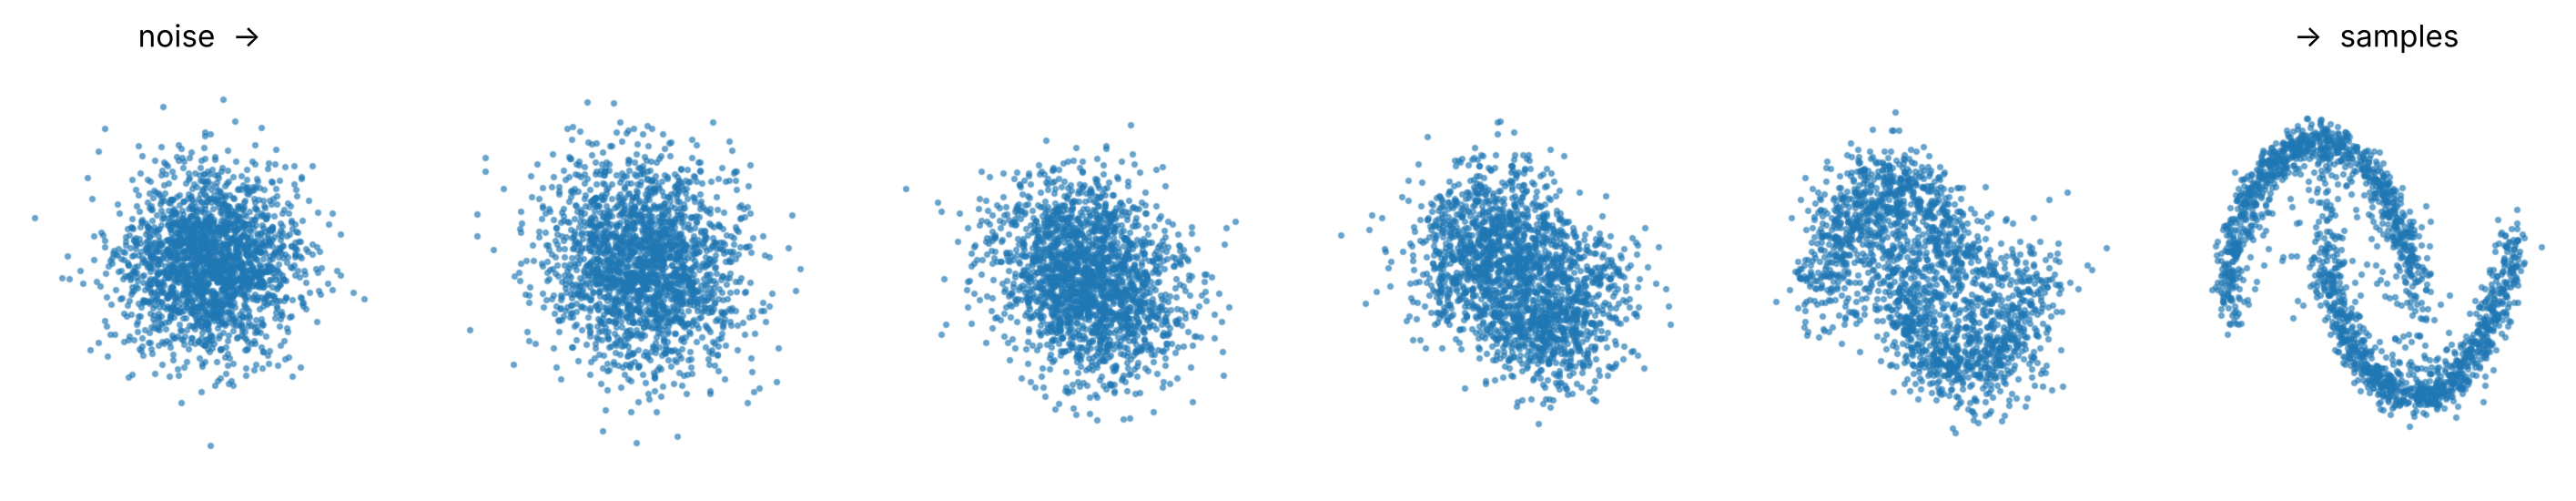

In [8]:
@torch.no_grad()
def ddpm_sample(model, n=2000, c=None):
    x = torch.randn(n, 2, device=device)
    traj = [x.cpu().clone()]
    for ti in reversed(range(T)):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps = model(x, t, c) if c is not None else model(x, t)
        b, a, ab = betas[ti], alphas[ti], abar[ti]
        mean = (x - (b / (1 - ab).sqrt()) * eps) / a.sqrt()
        x = mean + (b.sqrt() * torch.randn_like(x) if ti > 0 else 0)
        if ti % 40 == 0: traj.append(x.cpu().clone())
    return x.cpu(), traj

samples, traj = ddpm_sample(model)
fig, axes = plt.subplots(1, len(traj), figsize=(3 * len(traj), 3))
for ax, xt in zip(axes, traj):
    ax.scatter(xt[:, 0], xt[:, 1], s=3, alpha=0.5); ax.axis("equal"); ax.axis("off")
axes[0].set_title("noise  →"); axes[-1].set_title("→  samples"); plt.show()

Now **DDIM**: deterministic, and it can skip timesteps. Implement one DDIM step and a strided schedule, then compare quality at 5, 10, 20 and 100 steps.

> **Important · clip the x₀ estimate.** With the cosine schedule, ᾱ at the last timestep is ≈ 6×10⁻⁸, so the first DDIM step divides by √ᾱ ≈ 2.5×10⁻⁴ and multiplies any error in ε̂ by about 4 000. DDPM does not have this problem because it never estimates x₀ explicitly. Since our data are standardised, clipping x₀ to [−3, 3] fixes it (this is `clip_sample` in the `diffusers` library).

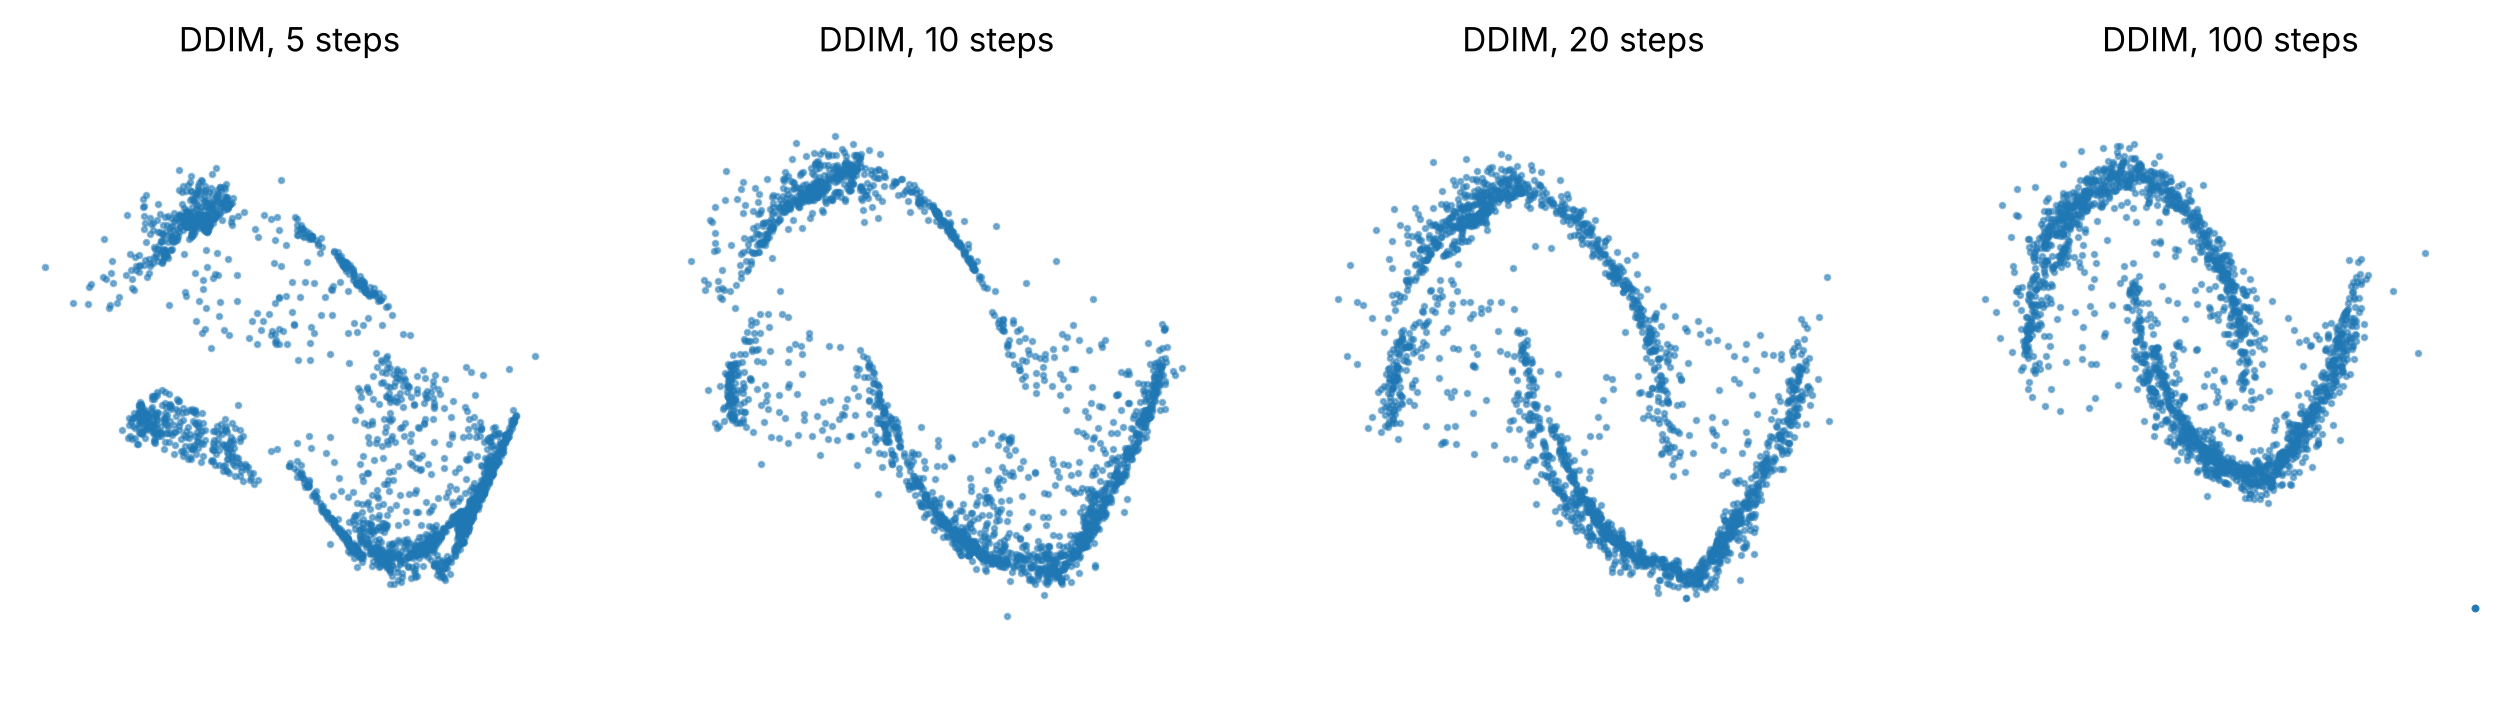

In [9]:
@torch.no_grad()
def ddim_sample(model, n=2000, steps=20, c=None):
    x = torch.randn(n, 2, device=device)
    ts = torch.linspace(T - 1, 0, steps).round().long()     # strided timesteps, high -> low
    for i, ti in enumerate(ts):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps = model(x, t, c) if c is not None else model(x, t)
        ab_t = abar[ti]
        ab_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x0 = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        x0 = x0.clamp(-3, 3)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.cpu()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, k in zip(axes, [5, 10, 20, 100]):
    s = ddim_sample(model, steps=k)
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.5); ax.set_title(f"DDIM, {k} steps"); ax.axis("equal"); ax.axis("off")
plt.show()

❓ **Q3.** Roughly how few DDIM steps still give clean moons? DDPM used all 200 steps and adds randomness; DDIM is deterministic. Time both for the same sample count (cell below). What is the practical trade-off, and how does it connect to the "quality–speed dial" from the lecture?

In [10]:
import time

def timed(fn):
    """Wall-clock time of fn(), waiting for the GPU to finish."""
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter(); fn()
    if device == "cuda": torch.cuda.synchronize()
    return time.perf_counter() - t0

t_ddpm = timed(lambda: ddpm_sample(model, n=2000))
print(f"DDPM (200 passos): {t_ddpm:.2f}s")
for k in [5, 10, 20, 50]:
    t_k = timed(lambda: ddim_sample(model, n=2000, steps=k))
    print(f"DDIM {k:3d} passos: {t_k:.2f}s  | {t_ddpm / t_k:.1f}x mais rápido que DDPM")

DDPM (200 passos): 0.40s
DDIM   5 passos: 0.01s  | 42.4x mais rápido que DDPM
DDIM  10 passos: 0.02s  | 21.3x mais rápido que DDPM
DDIM  20 passos: 0.04s  | 10.3x mais rápido que DDPM
DDIM  50 passos: 0.08s  | 5.2x mais rápido que DDPM


## Part 4 · Conditioning & classifier-free guidance (20 min)

Now we condition on the **moon label**. During training we sometimes drop the label (replace it with a "null" class) so the same model learns both the conditional and the unconditional noise — that is what makes classifier-free guidance possible.

In [11]:
NULL = 2   # the null/unconditional label (classes are 0 and 1)

def cond_loss(model, x0, c, p_drop=0.1):
    B = x0.shape[0]
    t = torch.randint(0, T, (B,), device=x0.device)
    noise = torch.randn_like(x0)
    xt = q_sample(x0, t, noise)
    c_in = c.clone()
    drop = torch.rand(B, device=x0.device) < p_drop
    c_in[drop] = NULL                                  # randomly drop the label
    return ((model(xt, t, c_in) - noise) ** 2).mean()

cmodel = Denoiser(n_classes=2).to(device)
opt = torch.optim.Adam(cmodel.parameters(), lr=2e-3)
Xd, yd = X.to(device), y.to(device)
for step in range(4000):
    idx = torch.randint(0, len(Xd), (512,), device=device)
    loss = cond_loss(cmodel, Xd[idx], yd[idx])
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 1000 == 0: print(f"step {step}: loss {loss.item():.3f}")
print("done")

step 0: loss 0.933


step 1000: loss 0.363


step 2000: loss 0.328


step 3000: loss 0.390


done


Classifier-free guidance combines the conditional and unconditional predictions:

$$\hat\varepsilon = \varepsilon_\varnothing + w\,(\varepsilon_c - \varepsilon_\varnothing)$$

Implement a guided DDIM sampler, then sweep the guidance scale `w`.

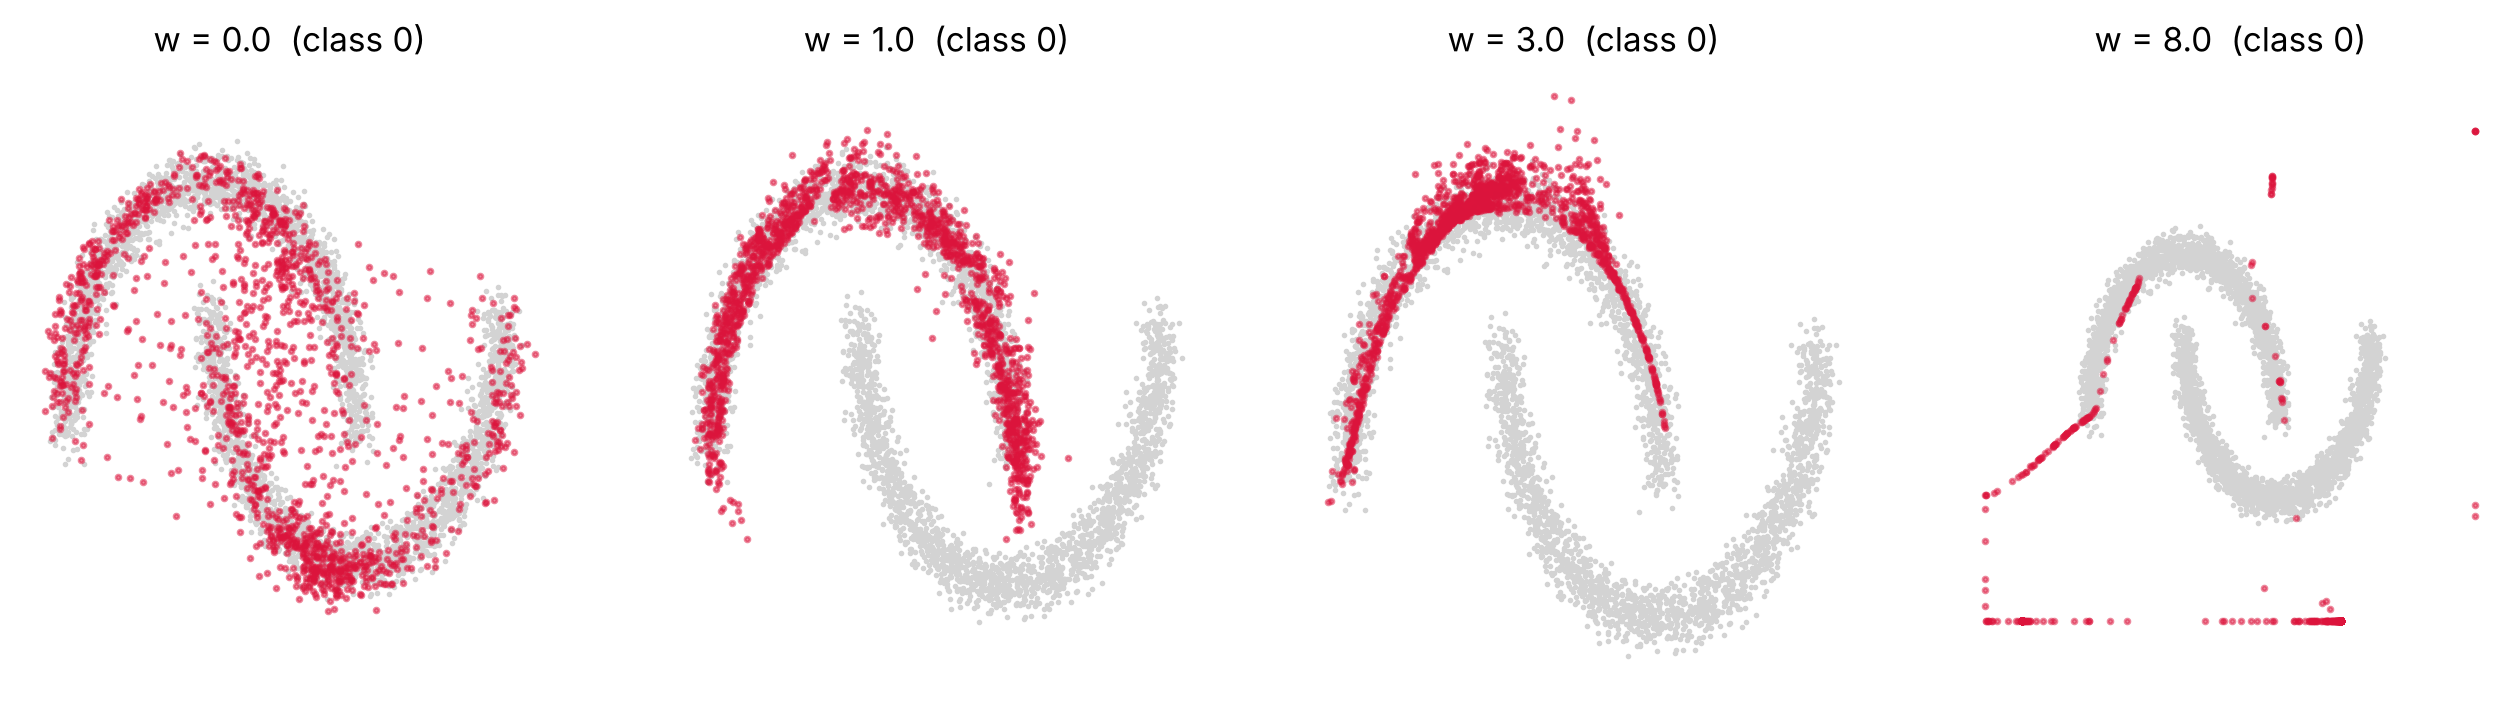

In [12]:
@torch.no_grad()
def guided_sample(model, label, n=1500, steps=50, w=3.0):
    x = torch.randn(n, 2, device=device)
    c = torch.full((n,), label, dtype=torch.long, device=device)
    null = torch.full((n,), NULL, dtype=torch.long, device=device)
    ts = torch.linspace(T - 1, 0, steps).round().long()
    for i, ti in enumerate(ts):
        t = torch.full((n,), ti, dtype=torch.long, device=device)
        eps_c = model(x, t, c)       # conditional prediction
        eps_u = model(x, t, null)    # unconditional prediction
        eps = eps_u + w * (eps_c - eps_u)
        ab_t = abar[ti]; ab_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x0 = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        x0 = x0.clamp(-3, 3)                 # same fix as in ddim_sample
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.cpu()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, w in zip(axes, [0.0, 1.0, 3.0, 8.0]):
    ax.scatter(X[:, 0], X[:, 1], s=1, c="lightgray")      # data, for reference
    s = guided_sample(cmodel, label=0, w=w)
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.5, c="crimson")
    ax.set_title(f"w = {w}  (class 0)"); ax.axis("equal"); ax.axis("off")
plt.show()

❓ **Q4.** At `w=0` you sample from *both* moons; by `w=3` the samples concentrate on class 0. What happens to **diversity** as `w` grows past 8 — do the points spread along the whole moon, or collapse? Relate this to "over-saturated / fried" images at high guidance in real text-to-image models.

## Part 5 · CLIP: zero-shot & retrieval (25 min)

Switch to multimodality. **CLIP** maps images and text into one shared space. We load a small pretrained CLIP and use it with **no fine-tuning**.

In [ ]:
import open_clip
clip_model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
tokenizer = open_clip.get_tokenizer("ViT-B-32")
clip_model = clip_model.to(device).eval()

def embed_texts(prompts):
    toks = tokenizer(prompts).to(device)
    with torch.no_grad():
        f = clip_model.encode_text(toks)
    return f / f.norm(dim=-1, keepdim=True)

def embed_images(pil_images):
    batch = torch.stack([preprocess(im) for im in pil_images]).to(device)
    with torch.no_grad():
        f = clip_model.encode_image(batch)
    return f / f.norm(dim=-1, keepdim=True)
print("CLIP loaded")

We need a few images. The next cell downloads a handful of varied photos from Wikimedia Commons.

> **⚠️ Plan B · if the classroom network blocks Wikimedia**
>
> If the next cell prints `skip` for (almost) every image (or stops with the message *“No images loaded”*), the safest option is to use local images:
>
> 1. Create a folder called `imagens` in the Colab file panel (📁 icon on the left → right-click → *New folder*).
> 2. Drag about five photos into it. Each file name becomes the label, so use names such as `dog.jpg`, `cat.jpg`, `car.jpg`, `pizza.jpg`, `beach.jpg`.
> 3. Run the cell again.
>
> Files uploaded to Colab are deleted when the session restarts; if that happens, repeat steps 1 and 2.

In [ ]:
from PIL import Image
import urllib.request, urllib.parse, io, os, glob

# Wikimedia Commons files (several candidates per label, in case one is renamed or removed).
# We request a 330 px width through Special:FilePath, because Wikimedia restricts
# thumbnails with non-standard widths (such as 320 px).
FILES = {
    "dog":   ["YellowLabradorLooking_new.jpg"],                       # ONE dog (used in Part 6)
    "cat":   ["Cat03.jpg"],
    "car":   ["2018_Ford_Focus_ST-Line_TDCi_1.5_Front.jpg",
              "2017_Toyota_Camry_(ASV70R)_SX_sedan_(2018-11-02)_01.jpg"],
    "pizza": ["Eq_it-na_pizza-margherita_sep2005_sml.jpg"],
    "beach": ["Big_Sandy_Bay_beach.jpg",
              "Gentle_waves_come_in_at_a_sandy_beach.JPG"],
}
EXTRA = {"dogs": ["Collage_of_Nine_Dogs.jpg"]}                         # MANY dogs (Part 6 only)

# Wikimedia requires an identifiable User-Agent; a bare "Mozilla/5.0" may be blocked.
HEADERS = {"User-Agent": "PL9-CLIP-lab/1.0 (teaching notebook; python-urllib)"}

def download(fname, width=330):
    url = ("https://commons.wikimedia.org/wiki/Special:FilePath/"
           + urllib.parse.quote(fname) + f"?width={width}")
    req = urllib.request.Request(url, headers=HEADERS)
    return Image.open(io.BytesIO(urllib.request.urlopen(req, timeout=15).read())).convert("RGB")

def load(files):
    imgs, nms = [], []
    for name, candidates in files.items():
        for fname in candidates:
            try:
                imgs.append(download(fname)); nms.append(name); break
            except Exception as e:
                print("skip", name, fname, "->", e)
    return imgs, nms

images, names = load(FILES)
extra_images, extra_names = load(EXTRA)

# Plan B: images uploaded by hand to the Colab folder "imagens/" (file name = label)
if len(images) < 3:
    for path in sorted(glob.glob("imagens/*")):
        try:
            images.append(Image.open(path).convert("RGB"))
            names.append(os.path.splitext(os.path.basename(path))[0])
        except Exception as e:
            print("skip", path, "->", e)

assert images, ("No images loaded. Create the folder 'imagens/' in Colab, upload a few photos "
                "to it (e.g. dog.jpg, cat.jpg, pizza.jpg) and run this cell again.")
print("loaded", names, "| extra", extra_names)

fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 3))
for ax, im, nm in zip(np.atleast_1d(axes), images, names):
    ax.imshow(im); ax.set_title(nm); ax.axis("off")
plt.show()

### Zero-shot classification

Build label prompts, embed images and texts, and classify by cosine similarity through a softmax. Fill `zero_shot`.

In [ ]:
LABELS = ["a dog", "a cat", "a car", "a pizza", "a beach", "a laptop", "a mountain"]

def zero_shot(pil_images, labels):
    img = embed_images(pil_images)
    txt = embed_texts(labels)
    with torch.no_grad():
        logits = clip_model.logit_scale.exp() * img @ txt.T
    return logits.softmax(dim=-1).cpu()

probs = zero_shot(images, LABELS)
for i, nm in enumerate(names):
    k = probs[i].argmax().item()
    print(f"{nm:6s} -> {LABELS[k]:10s}  ({probs[i, k]:.2f})")

❓ **Q5.** Zero-shot means CLIP was never trained on these exact labels. Did it get them right? Now rewrite the labels as bare words (`"dog"` not `"a dog"`) or add the classic prompt template (`"a photo of a dog"`). Does **prompt phrasing** change the result? This is *prompt engineering for vision*.

In [ ]:
CLASSES = ["dog", "cat", "car", "pizza", "beach", "laptop", "mountain"]
TEMPLATES = {"bare word": "{}", "a/an": "a {}", "a photo of": "a photo of a {}"}

img_emb = embed_images(images)
for tname, tpl in TEMPLATES.items():
    txt = embed_texts([tpl.format(c) for c in CLASSES])
    with torch.no_grad():
        p = (clip_model.logit_scale.exp() * img_emb @ txt.T).softmax(dim=-1).cpu()
    print(f"── {tname} ──")
    for i, nm in enumerate(names):
        k = p[i].argmax().item()
        cos_true = (img_emb[i] @ txt[CLASSES.index(nm)]).item() if nm in CLASSES else float("nan")
        print(f"  {nm:6s} -> {CLASSES[k]:9s} p={p[i, k]:.2f}  cos(verdadeira)={cos_true:.3f}")

### Image–text retrieval

Use the same embeddings the other way: given a text query, rank the images.

In [ ]:
def search(query, pil_images, names):
    q = embed_texts([query])
    img = embed_images(pil_images)
    sims = (img @ q.T).squeeze(1)
    order = sims.argsort(descending=True)
    return [(names[i], sims[i].item()) for i in order]

for q in ["something you can eat", "a place to relax on holiday", "a furry animal"]:
    ranking = search(q, images, names)
    print(f"{q:32s} -> " + ", ".join(f"{n}({s:.2f})" for n, s in ranking[:3]))

❓ **Q6.** The query "something you can eat" never contains the word *pizza*, yet it should rank pizza first. Why does CLIP handle this, where a keyword search (BM25 from PL7) would fail? Connect this to dense retrieval and to the role CLIP plays as the "eyes" of a VLM.

## Part 6 · Probing a multimodal model (5 min)

CLIP judges *similarity* but cannot *reason*. Try to trip it up and see where the shared embedding is weak. We use two images: one with a single dog, and a collage with nine dogs.

In [ ]:
# Counting, relations and negation are classic CLIP weaknesses.
# We compare an image with ONE dog and an image with MANY dogs.
tricky = ["a dog", "one dog", "two dogs", "many dogs", "no dog", "a cat", "a dog to the left of a cat"]
probe = {}
if "dog" in names:       probe["one dog (Labrador)"] = images[names.index("dog")]
if "dogs" in extra_names: probe["nine dogs (collage)"] = extra_images[extra_names.index("dogs")]
if not probe:            probe["first image"] = images[0]

txt = embed_texts(tricky)
for title, im in probe.items():
    sims = (embed_images([im]) @ txt.T).squeeze(0)
    print(f"── image: {title} ──")
    for p, s in sorted(zip(tricky, sims.tolist()), key=lambda z: -z[1]):
        print(f"  {s:.3f}  {p}")

❓ **Q7.** Does CLIP reliably tell "one dog" from "two dogs", or "a dog" from "no dog"? Name one real task where this blind spot would cause a failure, and one architectural idea from the lecture (projector + LLM, native fusion) that could help.

## Part 7 · Results & report (5 min)

### Report

1. **Diffusion:** com 20 passos DDIM já saem duas luas reconhecíveis (10 passos ainda têm buracos, 5 estão partidas); 100 passos dão o resultado mais limpo. Tempo (2000 amostras, CPU): DDPM 200 passos = 0,40 s; DDIM 5 = 0,01 s (42x), 10 = 0,02 s (21x), 20 = 0,04 s (10x), 50 = 0,08 s (5x).
2. **Guidance:** `w` troca diversidade por fidelidade à classe (w maior = mais fiel ao rótulo, menos variedade).
3. **CLIP:** (confirmar com o output do Colab) sucesso esperado em classes visualmente claras (pizza, cão, gato); falha esperada com a etiqueta "a laptop"/"a mountain" ou com contagem. A frase usada muda as probabilidades, mas raramente a classe vencedora.
4. **Ligação:** nos dois casos há um espaço partilhado onde o texto condiciona a geração/classificação: o CLIP dá o embedding de texto que o denoiser usa como condição (cross-attention + CFG), e o mesmo CLIP é o "olho" dos VLMs.

### Respostas

- **Q1.** Com o cosine as luas deixam de se distinguir perto de t≈150 (ᾱ<0.1 em t=158); com o linear (escalado) perto de t≈100 (ᾱ<0.1 em t=94, ᾱ<0.5 em t=51 contra 99 no cosine). O linear destrói a estrutura mais cedo. Sem escalar, ᾱ final = 0,13 e nunca chega a ruído puro. Manter sinal mais tempo dá mais passos com informação útil para aprender a denoise, em vez de muitos passos já só com ruído.
- **Q2.** Para um mesmo x_t existem muitos (x0, ε) que o podem ter gerado, logo o ruído não é único. O melhor modelo prevê a média condicional, e a variância que sobra é erro irredutível (a loss ficou perto de 0,41).
- **Q3.** Com cerca de 20 passos já saem luas limpas. O DDPM é estocástico e usa 200 passos; o DDIM é determinístico e salta passos (20 passos = 10x mais rápido). Compromisso: menos passos = mais rápido mas menos qualidade, é o "dial qualidade-velocidade" da aula (retornos decrescentes depois de umas dezenas de passos).
- **Q4.** Com w=8 não se espalham pela lua: os pontos colapsam e saem da lua, ficam em linhas e nos limites do clip (−3). A diversidade desaparece e as amostras saem da distribuição. É o equivalente às imagens saturadas / "fritas" em guidance alto nos modelos de imagem.
- **Q5.** (confirmar com o output) O CLIP acerta sem ter visto estas etiquetas. A formulação muda as probabilidades e as similaridades, sobretudo com a palavra solta; "a photo of a ..." tende a dar valores mais altos e estáveis. É prompt engineering para visão.
- **Q6.** O CLIP alinha imagens e texto no mesmo espaço (treino contrastivo), por isso "something you can eat" fica perto do embedding da pizza sem a palavra aparecer. O BM25 só compara palavras iguais. É retrieval denso, e o CLIP é o "olho" dos VLMs.
- **Q7.** (confirmar com o output) Não é fiável a distinguir "one dog" de "two dogs" nem "a dog" de "no dog": o treino contrastivo otimiza a correspondência global imagem-texto, não contar nem negar. Falha, por exemplo, ao contar peças num inventário por foto. Ajuda: projector + LLM (VLM) com patches da imagem, ou fusão nativa.


## ★ Bonus (at home or for fast teams)

**B1 · Real image diffusion.** Use `diffusers` to run a pretrained latent diffusion model, and reproduce the Part 3 and Part 4 experiments on real images: sweep the number of inference steps and the guidance scale.

In [ ]:
# TODO (optional, needs a GPU): load a StableDiffusionPipeline from `diffusers`
#   ("stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.float16), then:
#   - sweep num_inference_steps (e.g. 5, 10, 25, 50) at guidance_scale 7.5   (Part 3 on real images)
#   - sweep guidance_scale (e.g. 1.0, 3.0, 7.5, 15.0) at 25 steps           (Part 4 on real images)
#   Use the same seed in every panel: generator=torch.Generator("cuda").manual_seed(0)
...

**B2 · CLIP-guided caption search (HyDE flavour).** For a query, ask an LLM (or write by hand) a *hypothetical caption*, embed that with CLIP's text encoder, and retrieve — compare with embedding the raw query. Does the richer caption retrieve better? This is the HyDE idea from PL7, now across modalities.

**B3 · Interpolation.** Pick two noise seeds, run `guided_sample` while linearly interpolating between them, and watch the sample move across the data manifold. Where does it leave the moons?